In [2]:
import pandas as pd

df = pd.read_csv(r"D:\My Downloads\job posting\fake_job_postings.csv")

print(df.shape)                      # (rows, columns)
print(df.columns.tolist())           # column names
df.info()                            # data types + non-null counts

print(df.isna().sum().sort_values(ascending=False))   # missing values

# job_id har row ka unique hai, is liye usay hata kar duplicates dhoondo
print("Duplicates:", df.drop(columns="job_id").duplicated().sum())

print(df["fraudulent"].value_counts())
print(df["fraudulent"].value_counts(normalize=True) * 100)

(17880, 18)
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']
<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 no

Removed: 281 | Remaining: 17599
(14079, 18) (3520, 18)
4.86540237232758 4.857954545454545


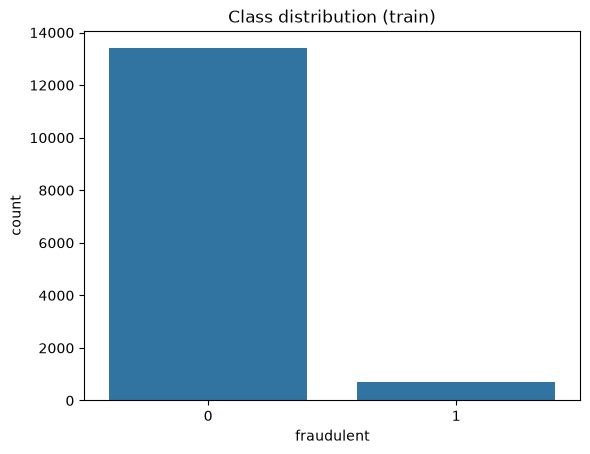

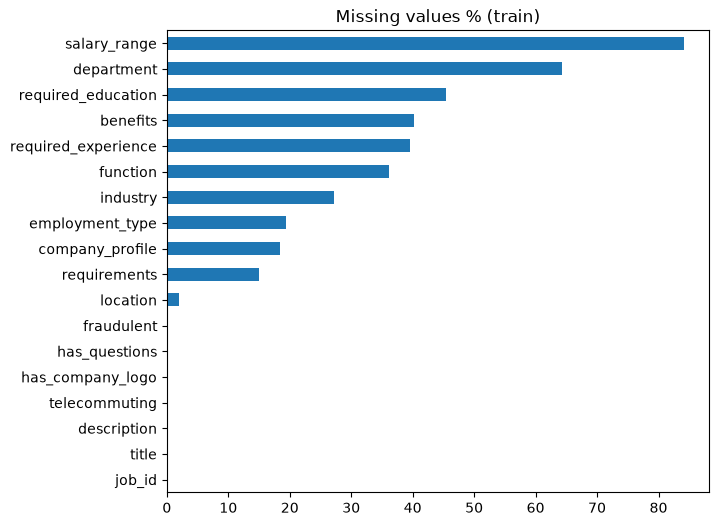

has_company_logo 
 has_company_logo
0    15.632582
1     2.090406
Name: fraudulent, dtype: float64 

has_questions 
 has_questions
0    6.938434
1    2.718334
Name: fraudulent, dtype: float64 

telecommuting 
 telecommuting
0    4.693756
1    8.768971
Name: fraudulent, dtype: float64 



In [13]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv(r"D:\My Downloads\job posting\fake_job_postings.csv")

# 1. Duplicates (job_id ke baghair)
before = len(df)
df = df.drop_duplicates(subset=df.columns.drop("job_id")).reset_index(drop=True)
print("Removed:", before - len(df), "| Remaining:", len(df))

# 2. Stratified split
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df["fraudulent"], random_state=42
)
print(train_df.shape, test_df.shape)
print(train_df["fraudulent"].mean() * 100, test_df["fraudulent"].mean() * 100)

# 3. Split save karo
os.makedirs("../data/processed", exist_ok=True)
train_df.to_csv("../data/processed/train.csv", index=False)
test_df.to_csv("../data/processed/test.csv", index=False)

# 4. EDA (sirf train par)
sns.countplot(x="fraudulent", data=train_df)
plt.title("Class distribution (train)")
plt.show()

(train_df.isna().mean() * 100).sort_values().plot(kind="barh", figsize=(7, 6))
plt.title("Missing values % (train)")
plt.show()

for col in ["has_company_logo", "has_questions", "telecommuting"]:
    print(col, "\n", train_df.groupby(col)["fraudulent"].mean() * 100, "\n")

In [4]:
import sys
import os

# Root folder ke andar 'src' ka absolute path add karna
current_dir = os.getcwd()
src_dir = os.path.abspath(os.path.join(current_dir, '..', 'src'))
if src_dir not in sys.path:
    sys.path.append(src_dir)

import pandas as pd
from feature_engineering import add_features

# Baaki ka code...
train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")

train_fe = add_features(train)
test_fe = add_features(test)

num_cols = ["text_len", "word_count", "has_salary", "missing_company_profile",
            "has_url_placeholder", "has_email_placeholder",
            "fee_request", "urgency_words", "caps_ratio"]

print(train_fe.groupby("fraudulent")[num_cols].mean().T)

fraudulent                         0            1
text_len                 2699.601911  2104.626277
word_count                379.261834   285.262774
has_salary                  0.154248     0.258394
missing_company_profile     0.159474     0.667153
has_url_placeholder         0.316709     0.340146
has_email_placeholder       0.066074     0.197080
fee_request                 0.004181     0.001460
urgency_words               0.092952     0.084672
caps_ratio                  0.037663     0.048505


In [5]:
print("URL placeholders:", train["description"].str.contains("#URL_", na=False).sum())

train_fe.to_csv("../data/processed/train_fe.csv", index=False)
test_fe.to_csv("../data/processed/test_fe.csv", index=False)
print("Saved:", train_fe.shape, test_fe.shape)

URL placeholders: 2591
Saved: (14079, 28) (3520, 28)


In [6]:
print(train_fe["fraudulent"].mean() * 100)
print(test_fe["fraudulent"].mean() * 100)

4.86540237232758
4.857954545454545


In [7]:
import sys, importlib
sys.path.append("../src")
import pandas as pd
import data_preprocessing
importlib.reload(data_preprocessing)          # nayi file dobara load
from data_preprocessing import build_preprocessor, ALL_FEATURES
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

train = pd.read_csv("../data/processed/train_fe.csv")
train["text_clean"] = train["text_clean"].fillna("")
X_train, y_train = train[ALL_FEATURES], train["fraudulent"]

models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, class_weight="balanced"), "standard"),
    "Linear SVM": (LinearSVC(class_weight="balanced", max_iter=10000), "standard"),
    "Multinomial NB":      (MultinomialNB(), "minmax"),
    "Decision Tree":       (DecisionTreeClassifier(class_weight="balanced", random_state=42), "standard"),
    "Random Forest":       (RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                   n_jobs=-1, random_state=42), "standard"),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ["average_precision", "recall", "precision", "f1"]
rows = []
for name, (clf, scaler) in models.items():
    pipe = Pipeline([("prep", build_preprocessor(scaler)), ("clf", clf)])
    sc = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metrics)
    rows.append({"model": name, **{m: sc[f"test_{m}"].mean() for m in metrics}})
    print("done:", name)

results = pd.DataFrame(rows).set_index("model").round(3)
print(results.sort_values("average_precision", ascending=False))

done: Logistic Regression
done: Linear SVM
done: Multinomial NB
done: Decision Tree
done: Random Forest
                     average_precision  recall  precision     f1
model                                                           
Linear SVM                       0.904   0.831      0.843  0.836
Random Forest                    0.883   0.578      0.985  0.728
Logistic Regression              0.849   0.873      0.575  0.692
Multinomial NB                   0.582   0.168      0.747  0.272
Decision Tree                    0.466   0.704      0.641  0.671


In [8]:
from sklearn.model_selection import GridSearchCV

def tune(clf, grid, scaler="standard"):
    pipe = Pipeline([("prep", build_preprocessor(scaler)), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="average_precision",
                      n_jobs=1, refit=True, error_score="raise")
    gs.fit(X_train, y_train)
    return gs

svm_gs = tune(
    LinearSVC(class_weight="balanced", max_iter=10000),
    {"clf__C": [0.03, 0.1, 0.3, 1, 3]},
)
print("SVM best:", svm_gs.best_params_, round(svm_gs.best_score_, 3))

rf_gs = tune(
    RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=42),
    {"clf__n_estimators": [200, 400], "clf__min_samples_leaf": [1, 2]},
)
print("RF best:", rf_gs.best_params_, round(rf_gs.best_score_, 3))

SVM best: {'clf__C': 3} 0.905
RF best: {'clf__min_samples_leaf': 1, 'clf__n_estimators': 400} 0.889


In [9]:
import joblib
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (precision_recall_curve, precision_score, recall_score,
                             f1_score, accuracy_score, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             classification_report)

# ---- 1. Threshold: sirf train ke out-of-fold scores se ----
best_svm = svm_gs.best_estimator_
oof = cross_val_predict(clone(best_svm), X_train, y_train, cv=cv,
                        method="decision_function", n_jobs=-1)
p, r, t = precision_recall_curve(y_train, oof)
f1 = 2 * p * r / (p + r + 1e-12)
i = f1[:-1].argmax()
thr = t[i]
print(f"Chosen threshold: {thr:.3f} | OOF precision {p[i]:.3f} recall {r[i]:.3f} F1 {f1[i]:.3f}")

# ---- 2. Test data load ----
test = pd.read_csv("../data/processed/test_fe.csv")
test["text_clean"] = test["text_clean"].fillna("")
X_test, y_test = test[ALL_FEATURES], test["fraudulent"]

# ---- 3. Saare models ek hi test set par ----
final_models = {
    "Logistic Regression": Pipeline([("prep", build_preprocessor("standard")),
                                     ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Linear SVM (tuned)": best_svm,
    "Multinomial NB": Pipeline([("prep", build_preprocessor("minmax")), ("clf", MultinomialNB())]),
    "Decision Tree": Pipeline([("prep", build_preprocessor("standard")),
                               ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=42))]),
    "Random Forest (tuned)": rf_gs.best_estimator_,
}

def get_scores(model, X):
    clf = model.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

rows = []
for name, m in final_models.items():
    if name not in ("Linear SVM (tuned)", "Random Forest (tuned)"):
        m.fit(X_train, y_train)          # tuned models pehle se train par fit hain
    pred = m.predict(X_test)
    s = get_scores(m, X_test)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred),
                 "roc_auc": roc_auc_score(y_test, s),
                 "pr_auc": average_precision_score(y_test, s)})
print(pd.DataFrame(rows).set_index("model").round(3).sort_values("pr_auc", ascending=False))

# ---- 4. Final model: default vs chosen threshold ----
s_test = best_svm.decision_function(X_test)
for label, pred in [("default threshold", best_svm.predict(X_test)),
                    ("chosen threshold", (s_test >= thr).astype(int))]:
    print("\n==", label, "==")
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, target_names=["genuine", "fraud"], digits=3))

# ---- 5. Model aur threshold save ----
import os
os.makedirs("../models", exist_ok=True)
joblib.dump({"pipeline": best_svm, "threshold": float(thr)}, "../models/job_svm.joblib")

Chosen threshold: 0.130 | OOF precision 0.923 recall 0.782 F1 0.847
                       accuracy  precision  recall     f1  roc_auc  pr_auc
model                                                                     
Linear SVM (tuned)        0.988      0.922   0.830  0.874    0.989   0.919
Random Forest (tuned)     0.980      1.000   0.591  0.743    0.992   0.917
Logistic Regression       0.967      0.605   0.924  0.731    0.991   0.888
Multinomial NB            0.957      0.702   0.193  0.303    0.947   0.604
Decision Tree             0.968      0.646   0.749  0.694    0.864   0.496

== default threshold ==
[[3337   12]
 [  29  142]]
              precision    recall  f1-score   support

     genuine      0.991     0.996     0.994      3349
       fraud      0.922     0.830     0.874       171

    accuracy                          0.988      3520
   macro avg      0.957     0.913     0.934      3520
weighted avg      0.988     0.988     0.988      3520


== chosen threshold ==
[[33

['../models/job_svm.joblib']

In [10]:
import numpy as np
import os

prep = best_svm.named_steps["prep"]
clf = best_svm.named_steps["clf"]
names = prep.get_feature_names_out()
coef = clf.coef_[0]

coef_df = pd.DataFrame({"feature": names, "coef": coef})
print("== Fraud ki taraf (top 20) ==")
print(coef_df.sort_values("coef", ascending=False).head(20).to_string(index=False))
print("\n== Genuine ki taraf (top 20) ==")
print(coef_df.sort_values("coef").head(20).to_string(index=False))

os.makedirs("../reports", exist_ok=True)
coef_df.to_csv("../reports/svm_coefficients.csv", index=False)

# ---- Ek job ki wajah ----
def explain_job(row_df, top_n=8):
    X = prep.transform(row_df)
    X = X.toarray()[0] if hasattr(X, "toarray") else X[0]
    contrib = X * coef
    score = contrib.sum() + clf.intercept_[0]
    order = np.argsort(contrib)
    up = [(names[i], contrib[i]) for i in order[::-1][:top_n] if contrib[i] > 0]
    down = [(names[i], contrib[i]) for i in order[:top_n] if contrib[i] < 0]
    return score, up, down

idx = np.where((y_test.values == 1) & (s_test >= thr))[0][0]   # ek sahi pakri hui fake job
score, up, down = explain_job(X_test.iloc[[idx]])
print("\nExplain score:", round(score, 3), "| model ka score:", round(s_test[idx], 3))
print("Fraud ki taraf:", [(n, round(c, 3)) for n, c in up])
print("Genuine ki taraf:", [(n, round(c, 3)) for n, c in down])

== Fraud ki taraf (top 20) ==
                        feature     coef
                   text__accion 2.651920
               text__using link 2.102076
                 text__novation 1.849630
              text__apply using 1.773961
                     text__link 1.643401
                 text__supplier 1.576791
        text__aptitude staffing 1.558364
          text__sales executive 1.552241
                   text__church 1.496744
                text__financing 1.481842
                 text__aptitude 1.478989
              text__engineering 1.462543
                  text__timejob 1.427017
                    text__money 1.419739
                 text__american 1.417156
                     text__real 1.412451
                 text__industry 1.406075
text__manufacturing environment 1.392457
            text__field service 1.380035
                 text__time amp 1.360263

== Genuine ki taraf (top 20) ==
                  feature      coef
         text__commission -1.509106
    

In [11]:
p, r, t = precision_recall_curve(y_train, oof)
hi = t[np.where(p[:-1] >= 0.90)[0][0]]
lo = t[np.where(r[:-1] >= 0.95)[0][-1]]
print(f"lo = {lo:.3f} | hi = {hi:.3f}")
assert lo < hi, "lo hi se chhota hona chahiye"

def triage(scores):
    return np.where(scores >= hi, "Potentially Fraudulent",
           np.where(scores <= lo, "Likely Legitimate", "Uncertain / Manual Verification"))

tier = triage(s_test)
print(pd.crosstab(tier, y_test, rownames=["tier"], colnames=["actual (1=fake)"]))

joblib.dump({"pipeline": best_svm, "threshold": float(thr),
             "lo": float(lo), "hi": float(hi)}, "../models/job_svm.joblib")

lo = -0.938 | hi = 0.082
actual (1=fake)                     0    1
tier                                      
Likely Legitimate                3037    7
Potentially Fraudulent             11  139
Uncertain / Manual Verification   301   25


['../models/job_svm.joblib']

In [12]:
pd.DataFrame(rows).set_index("model").round(3).to_csv("../reports/test_results.csv")
pd.crosstab(tier, y_test, rownames=["tier"], colnames=["actual"]).to_csv("../reports/tier_crosstab.csv")